In [266]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

In [267]:
#cargar dataset
iris = load_iris()
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [268]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [269]:
X = iris.data[:, [2,3]]
X.shape

(150, 2)

Text(0.5, 1.0, 'Iris Dataset')

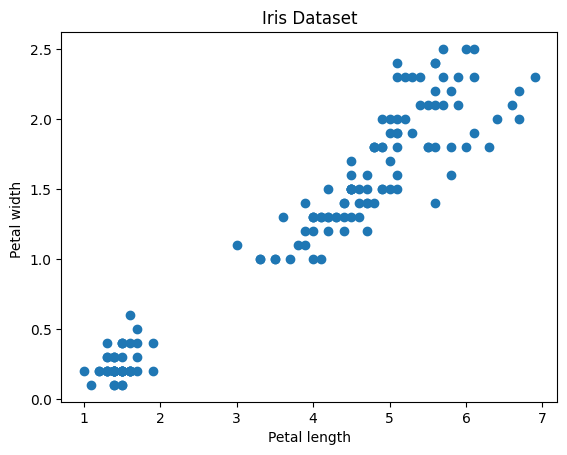

In [270]:
plt.scatter(X[:,0], X[:,1])
plt.xlabel("Petal length")
plt.ylabel("Petal width ")
plt.title("Iris Dataset")

In [271]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**Crear GMM**
Creare 3 clusters = 3 Gaussianas

covariance_type="spherical" "diag" "tied" "full"

In [272]:
miGMM = GaussianMixture(n_components=3,random_state=42, covariance_type="full", n_init=1)

In [273]:
miGMM.fit(X_scaled)

GaussianMixture(n_components=3, random_state=42)

In [274]:
# NUmero de iteraciones para converger
miGMM.converged_

True

In [275]:
labels = miGMM.predict(X_scaled)
labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

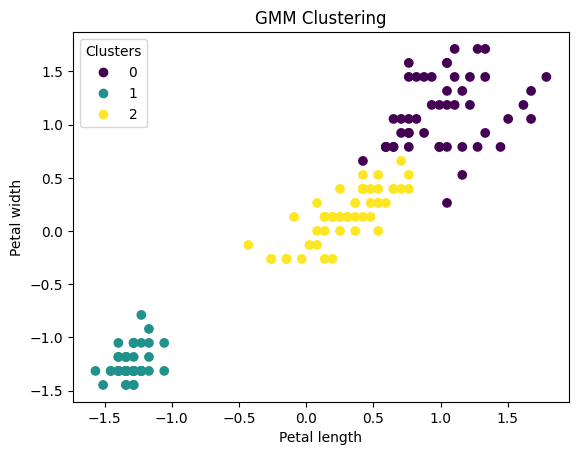

In [276]:
scatter_plot =plt.scatter(X_scaled[:,0],  X_scaled[:,1], c=labels )
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("GMM Clustering")
plt.legend(*scatter_plot.legend_elements(), title="Clusters")
plt.show()
# * desenpaqueta la infoq tiene almacenada plt.scatter que es "observacion-cluster"

In [277]:
probabilidades = miGMM.predict_proba(X_scaled)

#np.round(probabilidades[:10]*100)
np.round(probabilidades*100)

array([[  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
       [  0., 100.,   0.],
 

In [278]:
indice = np.where(np.round(probabilidades[:, 0] * 100) == 46)
indice

(array([77]),)

In [279]:
print(np.round(probabilidades[83]*100))
labels[83]

[31.  0. 69.]


np.int64(2)

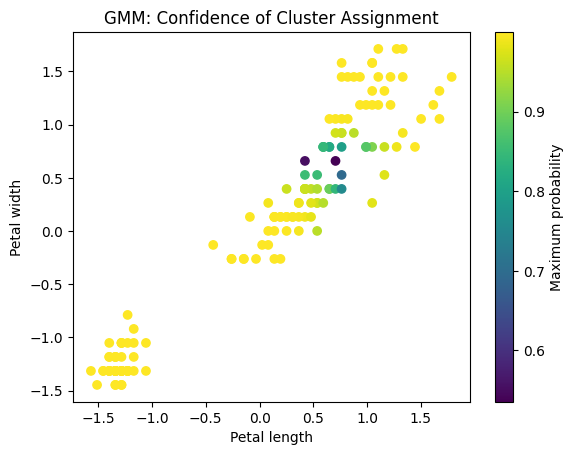

In [280]:
confidence = probabilidades.max(axis=1)

plt.scatter(X_scaled[:, 0],X_scaled[:, 1],c=confidence)

plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("GMM: Confidence of Cluster Assignment")
plt.colorbar(label="Maximum probability")
plt.show()

In [281]:
print("Medias:")
print(miGMM.means_)

print("\nCovarianzas:")
print(miGMM.covariances_)

print("\nPesos:")
print(miGMM.weights_)

Medias:
[[ 1.0174453   1.09482233]
 [-1.30498753 -1.25489382]
 [ 0.29899444  0.17473848]]

Covarianzas:
[[[0.10050414 0.03850322]
  [0.03850322 0.12690783]]

 [[0.00954901 0.00445003]
  [0.00445003 0.01885965]]

 [[0.07780701 0.05846413]
  [0.05846413 0.06984178]]]

Pesos:
[0.32801909 0.33333295 0.33864796]
